In [1]:
import pandas as pd
from sqlalchemy import create_engine,URL,text

In [2]:
def data_extraction():
    connection_url = URL.create(
        drivername="mysql+pymysql",
        username= "root",
        password="Shantanu@2026",
        host="localhost",
        port = 3306,
        database= "test_case_5"
    )
    engine = create_engine(connection_url)

    df = pd.read_sql("SELECT * FROM daily_sales",engine)

    return df

In [3]:
df = data_extraction()

In [4]:
df.head()

,sale_id,sale_date,product_name,quantity,unit_price,total_amount
0,1,2026-01-01,Laptop,2,50000.0,100000.0
1,2,2026-01-01,Mouse,5,500.0,2500.0
2,3,2026-01-01,Keyboard,3,1200.0,3600.0
3,4,2026-01-02,Laptop,1,50000.0,50000.0
4,5,2026-01-02,Monitor,2,12000.0,24000.0


In [ ]:
def data_transformation(df):
    df["sale_date"] = pd.to_datetime(df["sale_date"])
    df["Day"] = df["sale_date"].dt.day 
    df["Year"] = df["sale_date"].dt.year 
    df["Month"] = df["sale_date"].dt.month 

    return df

In [6]:
new_df = data_transformation(data_extraction())

In [9]:
new_df.head()

new_df.columns

Index(['sale_id', 'sale_date', 'product_name', 'quantity', 'unit_price',
       'total_amount', 'Day', 'Year', 'Month'],
      dtype='str')

In [49]:
monthly_trend = (new_df.groupby(["Year","Month"],as_index=False)["total_amount"].sum().rename(columns={"total_amount": "monthly_revenue"}).sort_values(["Year","Month"]))
monthly_trend["prev_month_revenue"] =monthly_trend["monthly_revenue"].shift(1)

In [50]:
monthly_trend

,Year,Month,monthly_revenue,prev_month_revenue
0,2024,1,198500.0,NaN
1,2024,2,295000.0,198500.0
2,2024,3,310700.0,295000.0
3,2024,4,258800.0,310700.0
4,2024,5,519700.0,258800.0
5,2024,6,264600.0,519700.0
6,2024,7,333600.0,264600.0
7,2024,8,327600.0,333600.0
8,2024,9,340050.0,327600.0
9,2024,10,567700.0,340050.0


In [51]:
monthly_trend["mom_growth_perct"] = ((monthly_trend["monthly_revenue"] - monthly_trend["prev_month_revenue"])/monthly_trend["prev_month_revenue"]) *100

In [52]:
monthly_trend

,Year,Month,monthly_revenue,prev_month_revenue,mom_growth_perct
0,2024,1,198500.0,NaN,NaN
1,2024,2,295000.0,198500.0,48.614610
2,2024,3,310700.0,295000.0,5.322034
3,2024,4,258800.0,310700.0,-16.704216
4,2024,5,519700.0,258800.0,100.811437
5,2024,6,264600.0,519700.0,-49.086011
6,2024,7,333600.0,264600.0,26.077098
7,2024,8,327600.0,333600.0,-1.798561
8,2024,9,340050.0,327600.0,3.800366
9,2024,10,567700.0,340050.0,66.946037


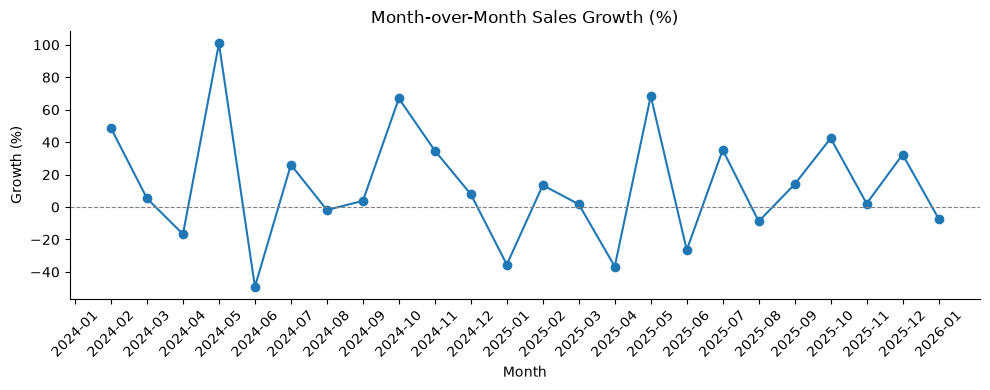

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(monthly_trend["Period"], monthly_trend["mom_growth_perct"], marker="o")

# Add a faint 0% reference line to easily separate growth (+) from decline (-)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)

plt.title("Month-over-Month Sales Growth (%)")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.xticks(rotation=45)
plt.gca().spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

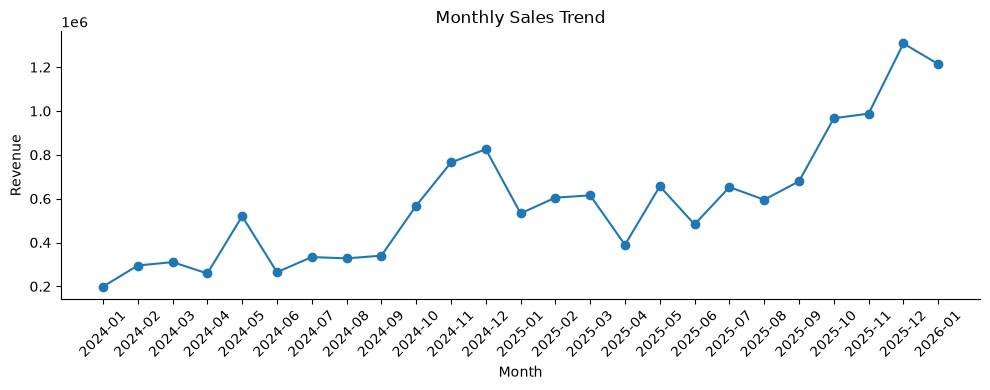

In [57]:
import matplotlib.pyplot as plt

monthly_trend["Period"] = (
    monthly_trend["Year"].astype(str)
    + "-"
    + monthly_trend["Month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(10, 4))
plt.plot(monthly_trend["Period"], monthly_trend["monthly_revenue"], marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

# Remove top and right borders for a clean, minimalist look
plt.gca().spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()